In [ ]:
from google.colab import files

files.download('/content/psychological_analysis_results.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download('/content/psychological_analysis_results.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

for root, dirs, files in os.walk('/content'):
    for file in files:
        if file.endswith(('.csv', '.xlsx')):
            print(os.path.join(root, file))

/content/psychological_analysis_results.xlsx
/content/project_summary.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_test.csv


In [ ]:

# Export final analysis tables

summary = pd.DataFrame({
    "Metric": [
        "Total Students",
        "Average Attendance",
        "Average Final Score",
        "Attendance-Final Score Correlation"
    ],
    "Value": [
        len(df),
        df["Attendance_Percentage"].mean(),
        df["Final_Score"].mean(),
        df["Attendance_Percentage"].corr(df["Final_Score"])
    ]
})

psychological_tables = {}

for factor in [
    "Family_Pressure_Level",
    "Self_Motivation_Level",
    "Stress_Level",
    "Peer_Support_Level",
    "Financial_Stress"
]:
    psychological_tables[factor] = (
        df.groupby(factor, dropna=False)
          .agg(
              Student_Count=("Student_ID", "count"),
              Average_Final_Score=("Final_Score", "mean"),
              Average_Attendance=("Attendance_Percentage", "mean")
          )
          .round(2)
    )

summary.to_csv("project_summary.csv", index=False)

with pd.ExcelWriter("psychological_analysis_results.xlsx") as writer:
    summary.to_excel(writer, sheet_name="Summary", index=False)
    for factor, table in psychological_tables.items():
        table.to_excel(writer, sheet_name=factor[:31])

print("Analysis results exported successfully.")


Analysis results exported successfully.


In [ ]:

# Final Analysis: Academic + Psychological Factors

print("========== DATASET SUMMARY ==========")
print("Total students:", len(df))
print("Average attendance:",
      round(df["Attendance_Percentage"].mean(), 2))
print("Average final score:",
      round(df["Final_Score"].mean(), 2))

print("\n========== ATTENDANCE ANALYSIS ==========")
print("Attendance and marks correlation:",
      round(df["Attendance_Percentage"].corr(
          df["Final_Score"]), 3))

factors = [
    "Family_Pressure_Level",
    "Self_Motivation_Level",
    "Stress_Level",
    "Peer_Support_Level",
    "Financial_Stress"
]

for factor in factors:
    print(f"\n========== {factor} ==========")
    print(
        df.groupby(factor, dropna=False)["Final_Score"]
          .agg(["count", "mean"])
          .round(2)
    )


========== DATASET SUMMARY ==========
Total students: 200
Average attendance: 79.27
Average final score: 70.64

========== ATTENDANCE ANALYSIS ==========
Attendance and marks correlation: 0.105

========== Family_Pressure_Level ==========
                       count   mean
Family_Pressure_Level              
1                         15  70.65
2                         25  70.24
3                         53  69.04
4                         44  70.62
5                         30  69.79
6                         14  74.99
7                         11  77.64
8                          5  67.76
9                          2  73.60
10                         1  61.20

========== Self_Motivation_Level ==========
                       count   mean
Self_Motivation_Level              
1                          3  70.53
2                          4  69.35
3                          7  72.49
4                         17  71.25
5                         24  68.05
6                         30  72

In [ ]:
factors = [
    "Family_Pressure_Level",
    "Self_Motivation_Level",
    "Stress_Level",
    "Peer_Support_Level",
    "Financial_Stress"
]

for factor in factors:
    print("\n---", factor, "---")
    print(
        df.groupby(factor, dropna=False)["Final_Score"]
          .agg(["count", "mean"])
          .round(2)
    )


--- Family_Pressure_Level ---
                       count   mean
Family_Pressure_Level              
1                         15  70.65
2                         25  70.24
3                         53  69.04
4                         44  70.62
5                         30  69.79
6                         14  74.99
7                         11  77.64
8                          5  67.76
9                          2  73.60
10                         1  61.20

--- Self_Motivation_Level ---
                       count   mean
Self_Motivation_Level              
1                          3  70.53
2                          4  69.35
3                          7  72.49
4                         17  71.25
5                         24  68.05
6                         30  72.41
7                         44  68.45
8                         39  71.14
9                         18  75.02
10                        14  69.79

--- Stress_Level ---
              count   mean
Stress_Level             

In [ ]:
print("Attendance vs Final Score Correlation:")
print(df["Attendance_Percentage"].corr(df["Final_Score"]).round(3))

print("\nAverage score by attendance group:")
df["Attendance_Group"] = pd.cut(
    df["Attendance_Percentage"],
    bins=[0, 60, 75, 85, 100],
    labels=["Below 60", "60-75", "75-85", "85-100"],
    include_lowest=True
)

print(
    df.groupby("Attendance_Group", observed=False)["Final_Score"]
      .agg(["count", "mean"])
      .round(2)
)

Attendance vs Final Score Correlation:
0.105

Average score by attendance group:
                  count   mean
Attendance_Group              
Below 60              1  52.50
60-75                51  70.29
75-85               108  70.52
85-100               40  71.83


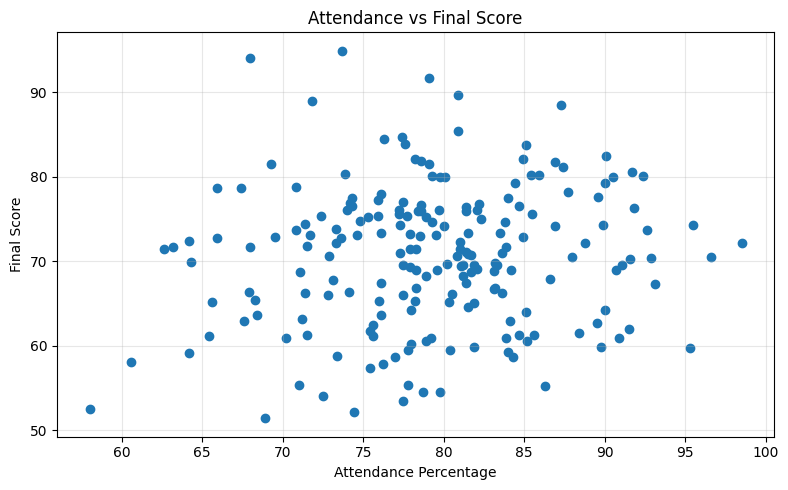

Attendance and Final Score Correlation: 0.105


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Attendance vs Final Score
plt.figure(figsize=(8, 5))
plt.scatter(df["Attendance_Percentage"], df["Final_Score"])
plt.title("Attendance vs Final Score")
plt.xlabel("Attendance Percentage")
plt.ylabel("Final Score")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Correlation
corr = df["Attendance_Percentage"].corr(df["Final_Score"])
print("Attendance and Final Score Correlation:", round(corr, 3))

In [ ]:
# Psychological factors vs academic performance
factors = [
    "Family_Pressure_Level",
    "Self_Motivation_Level",
    "Stress_Level",
    "Peer_Support_Level",
    "Financial_Stress"
]

for factor in factors:
    print("\n", factor)
    print(
        df.groupby(factor, dropna=False)
          .agg(
              Students=("Student_ID", "count"),
              Avg_Final_Score=("Final_Score", "mean"),
              Avg_Attendance=("Attendance_Percentage", "mean")
          )
          .round(2)
    )


 Family_Pressure_Level
                       Students  Avg_Final_Score  Avg_Attendance
Family_Pressure_Level                                           
1                            15            70.65           77.69
2                            25            70.24           82.26
3                            53            69.04           79.25
4                            44            70.62           78.80
5                            30            69.79           78.95
6                            14            74.99           77.77
7                            11            77.64           78.34
8                             5            67.76           81.42
9                             2            73.60           81.75
10                            1            61.20           75.60

 Self_Motivation_Level
                       Students  Avg_Final_Score  Avg_Attendance
Self_Motivation_Level                                           
1                             3           

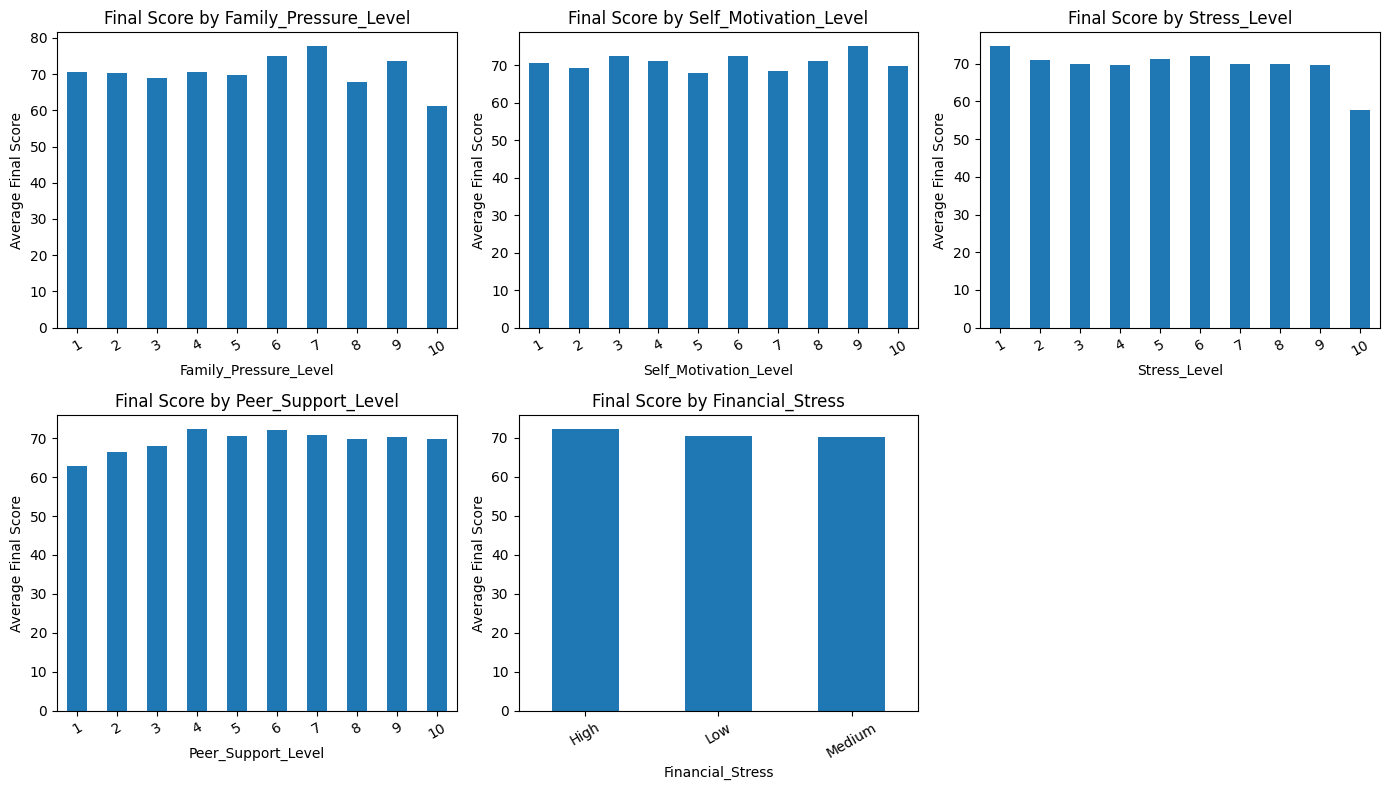

In [ ]:
factors = [
    "Family_Pressure_Level",
    "Self_Motivation_Level",
    "Stress_Level",
    "Peer_Support_Level",
    "Financial_Stress"
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, factor in enumerate(factors):
    summary = df.groupby(factor, dropna=False)["Final_Score"].mean()
    summary.plot(kind="bar", ax=axes[i])
    axes[i].set_title(f"Final Score by {factor}")
    axes[i].set_xlabel(factor)
    axes[i].set_ylabel("Average Final Score")
    axes[i].tick_params(axis="x", rotation=30)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

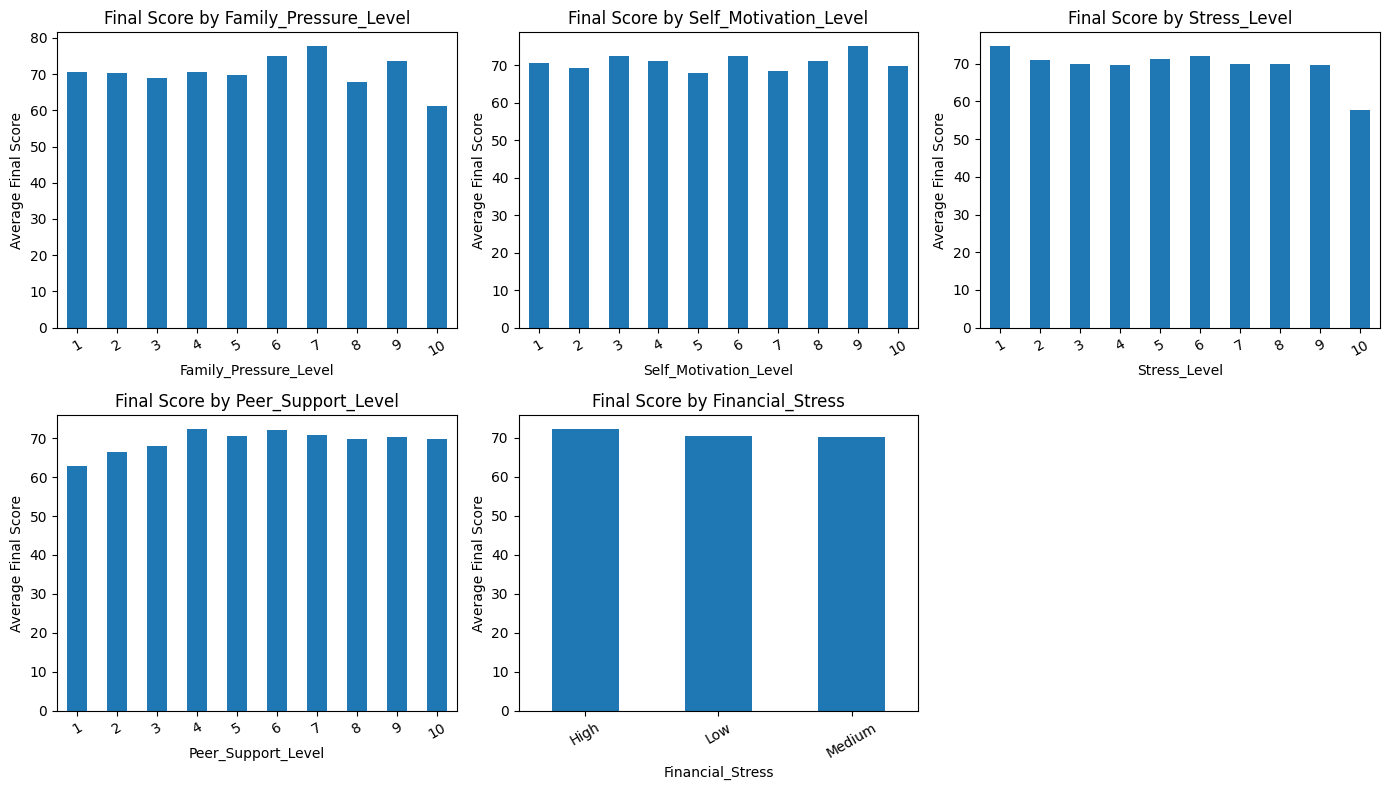

In [ ]:
factors = [
    "Family_Pressure_Level",
    "Self_Motivation_Level",
    "Stress_Level",
    "Peer_Support_Level",
    "Financial_Stress"
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, factor in enumerate(factors):
    summary = df.groupby(factor, dropna=False)["Final_Score"].mean()
    summary.plot(kind="bar", ax=axes[i])
    axes[i].set_title(f"Final Score by {factor}")
    axes[i].set_xlabel(factor)
    axes[i].set_ylabel("Average Final Score")
    axes[i].tick_params(axis="x", rotation=30)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Psychological factors vs academic performance
factors = [
    "Family_Pressure_Level",
    "Self_Motivation_Level",
    "Stress_Level",
    "Peer_Support_Level",
    "Financial_Stress"
]

for factor in factors:
    print("\n", factor)
    print(
        df.groupby(factor, dropna=False)
          .agg(
              Students=("Student_ID", "count"),
              Avg_Final_Score=("Final_Score", "mean"),
              Avg_Attendance=("Attendance_Percentage", "mean")
          )
          .round(2)
    )


 Family_Pressure_Level
                       Students  Avg_Final_Score  Avg_Attendance
Family_Pressure_Level                                           
1                            15            70.65           77.69
2                            25            70.24           82.26
3                            53            69.04           79.25
4                            44            70.62           78.80
5                            30            69.79           78.95
6                            14            74.99           77.77
7                            11            77.64           78.34
8                             5            67.76           81.42
9                             2            73.60           81.75
10                            1            61.20           75.60

 Self_Motivation_Level
                       Students  Avg_Final_Score  Avg_Attendance
Self_Motivation_Level                                           
1                             3           

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("/student_data.xlsx")

print("Dataset loaded:", df.shape)
print(df.head())

Dataset loaded: (200, 25)
  Student_ID            Name  Gender  Age Department  Semester  \
0    STU0001  Meera Malhotra  Female   22        MBA         8   
1    STU0002   Manish Sharma    Male   21        BBA         7   
2    STU0003     Simran Iyer  Female   21     B.Tech         3   
3    STU0004   Aarohi Sharma  Female   23     B.Tech         8   
4    STU0005    Reyansh Nair    Male   22     M.Tech         4   

  Previous_Qualification         Desired_Course Enrolled_Course  \
0         B.A. Economics                    MBA             MBA   
1              12th Arts                    BBA             BBA   
2  B.Sc Computer Science  M.Sc Computer Science          B.Tech   
3  B.Sc Computer Science  M.Sc Computer Science          B.Tech   
4  B.Sc Computer Science                 M.Tech          M.Tech   

  Course_Alignment  ... Financial_Stress  Counseling_Sessions_Attended  \
0          Aligned  ...              Low                             2   
1          Aligned  ...   

In [ ]:
import os
print(os.listdir('/content'))

['.config', 'sample_data']


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("/content/student_data.xlsx")

print("Dataset loaded:", df.shape)
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/student_data.xlsx'

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Attendance vs Final Score
plt.figure(figsize=(8, 5))
plt.scatter(df["Attendance_Percentage"], df["Final_Score"])
plt.title("Attendance vs Final Score")
plt.xlabel("Attendance Percentage")
plt.ylabel("Final Score")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Correlation
corr = df["Attendance_Percentage"].corr(df["Final_Score"])
print("Attendance and Final Score Correlation:", round(corr, 3))

NameError: name 'df' is not defined

<Figure size 800x500 with 0 Axes>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# 1. Basic dataset analysis
print("Dataset Shape:", df.shape)
print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

# 2. Important statistics
print("\nAverage Attendance:", round(df["Attendance_Percentage"].mean(), 2))
print("Average Final Score:", round(df["Final_Score"].mean(), 2))
print("\nDepartment-wise Average Final Score:")
print(df.groupby("Department")["Final_Score"].mean().round(2).sort_values(ascending=False))

# 3. Psychological factors summary
print("\nPsychological Factors:")
print(df[["Family_Pressure_Level", "Self_Motivation_Level",
          "Stress_Level", "Peer_Support_Level",
          "Financial_Stress"]].describe(include="all"))

In [ ]:
print("Total columns:")
print(df.columns.tolist())

print("\nFirst 3 student records:")
print(df.head(3).to_string())

In [ ]:
# Check data types and missing values

print("Data Types:")
print(df.dtypes)

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nUnique Values in Important Columns:")
for col in ['Course_Alignment', 'Financial_Stress',
            'Stress_Level', 'Attendance_Percentage']:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].value_counts().head(10))

Data Types:


NameError: name 'df' is not defined

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nStatistical Summary:")
print(df.describe(include="all").T)

In [ ]:
import pandas as pd

df = pd.read_excel("/content/student_data.xlsx")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()